# Phase 4: Modelling

In [20]:
# Import needed libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan


In [10]:

# Load the cleaned dataset
df = pd.read_csv('cleaned_master.csv')
df['week_start'] = pd.to_datetime(df['week_start'])

print(f"Loaded cleaned_master.csv: {df.shape[0]:,} rows across {df['category'].nunique()} categories.")

Loaded cleaned_master.csv: 46,800 rows across 7 categories.


## Model A: Price elasticity (log-log regression)

In [11]:
# -------------------------------------------------------------------------
# Model A: Log-Log Price Elasticity by Product Category
# -------------------------------------------------------------------------

results = []

# Estimate log-log regression per category
for cat in df['category'].unique():
    cat_data = df[df['category'] == cat]
    
    # Fit OLS model: log_units ~ log_price_ratio
    model = smf.ols('log_units ~ log_price_ratio', data=cat_data).fit()
    
    # Extract coefficient, 95% CI, p-value, and R-squared
    coef = model.params['log_price_ratio']
    ci = model.conf_int().loc['log_price_ratio']
    
    results.append({
        'Category': cat,
        'Elasticity (Beta)': round(coef, 4),
        '95% CI Lower': round(ci[0], 4),
        '95% CI Upper': round(ci[1], 4),
        'p-value': model.pvalues['log_price_ratio'],
        'R-squared': round(model.rsquared, 4)
    })

# Convert to DataFrame and rank from most price-sensitive (most negative) to least
elasticity_table = pd.DataFrame(results).sort_values('Elasticity (Beta)').reset_index(drop=True)
elasticity_table.index = elasticity_table.index + 1  # 1-based ranking

print("=== Category Price Elasticity Ranking (Model A) ===")
print(elasticity_table[['Category', 'Elasticity (Beta)', '95% CI Lower', '95% CI Upper', 'R-squared']])

=== Category Price Elasticity Ranking (Model A) ===
        Category  Elasticity (Beta)  95% CI Lower  95% CI Upper  R-squared
1         Snacks            -2.8323       -3.0711       -2.5935     0.0798
2      Beverages            -2.6506       -2.8317       -2.4695     0.0808
3  Fresh Produce            -2.4169       -2.6278       -2.2060     0.0748
4          Dairy            -2.2904       -2.5008       -2.0799     0.0680
5  Personal Care            -1.9634       -2.1673       -1.7596     0.0541
6      Household            -1.8639       -2.0730       -1.6549     0.0467
7        Staples            -1.8271       -2.0344       -1.6198     0.0457


## Model B: Multivariate demand model

In [12]:
# -------------------------------------------------------------------------
# Step 3: Define Predictors & Compute Variance Inflation Factors (VIF)
# -------------------------------------------------------------------------

# 1. Construct a chronological weekly time trend (1 to 104)
df['week_start'] = pd.to_datetime(df['week_start'])
df['trend'] = (df['week_start'] - df['week_start'].min()).dt.days // 7 + 1

# 2. Binary conversion for indicator variables
df['has_parking_binary'] = (df['has_parking'] == 'Yes').astype(int)

# 3. Candidate predictor list including both operational scale metrics
candidate_features = [
    'log_price_ratio', 'promo_flag', 'size_sqm', 'staff_count',
    'foot_traffic_index', 'competitors_2km', 'has_parking_binary',
    'avg_temp_c', 'rainfall_mm', 'holiday_week', 'trend', 
    'sin_season', 'cos_season'
]

# 4. Compute VIF for all candidate variables
X_candidates = df[candidate_features].copy()
X_candidates = sm.add_constant(X_candidates)

vif_data = pd.DataFrame({
    'Variable': X_candidates.columns,
    'VIF': [variance_inflation_factor(X_candidates.values, i) for i in range(X_candidates.shape[1])]
})

# Display VIF excluding the intercept constant, sorted descending
vif_table = vif_data[vif_data['Variable'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)

print("=== Variance Inflation Factor (VIF) Audit ===")
print(vif_table.to_string(index=False))

=== Variance Inflation Factor (VIF) Audit ===
          Variable       VIF
          size_sqm 33.079230
       staff_count 32.678436
        avg_temp_c  7.224129
        cos_season  6.992090
        sin_season  4.807762
       rainfall_mm  3.924778
   log_price_ratio  3.411568
        promo_flag  3.329739
             trend  1.301193
foot_traffic_index  1.246982
   competitors_2km  1.151324
      holiday_week  1.140996
has_parking_binary  1.067505


In [13]:
# -------------------------------------------------------------------------
# Step 4: Compare Model B Specifications (With vs. Without staff_count)
# -------------------------------------------------------------------------

# Model 1: Full specification containing collinear pair (size_sqm and staff_count)
formula_collinear = (
    'log_units ~ log_price_ratio + promo_flag + size_sqm + staff_count + '
    'foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + '
    'rainfall_mm + holiday_week + trend + sin_season + cos_season'
)
model_with_staff = smf.ols(formula_collinear, data=df).fit()

# Model 2: Parsimonious specification retaining physical floor capacity (size_sqm)
formula_clean = (
    'log_units ~ log_price_ratio + promo_flag + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + '
    'rainfall_mm + holiday_week + trend + sin_season + cos_season'
)
model_clean = smf.ols(formula_clean, data=df).fit()

# Comparison summary
comparison_df = pd.DataFrame({
    'Metric': ['R-squared', 'Adj. R-squared', 'AIC', 'BIC', 'size_sqm Coef', 'size_sqm Std Err'],
    'With staff_count (VIF ~ 33)': [
        round(model_with_staff.rsquared, 4),
        round(model_with_staff.rsquared_adj, 4),
        round(model_with_staff.aic, 1),
        round(model_with_staff.bic, 1),
        f"{model_with_staff.params['size_sqm']:.6f}",
        f"{model_with_staff.bse['size_sqm']:.7f}"
    ],
    'Without staff_count (VIF = 1.23)': [
        round(model_clean.rsquared, 4),
        round(model_clean.rsquared_adj, 4),
        round(model_clean.aic, 1),
        round(model_clean.bic, 1),
        f"{model_clean.params['size_sqm']:.6f}",
        f"{model_clean.bse['size_sqm']:.7f}"
    ]
})

print("=== Model Comparison: Multicollinearity Resolution ===")
print(comparison_df.to_string(index=False))

=== Model Comparison: Multicollinearity Resolution ===
          Metric With staff_count (VIF ~ 33) Without staff_count (VIF = 1.23)
       R-squared                      0.7196                           0.7194
  Adj. R-squared                      0.7195                           0.7193
             AIC                     33298.1                          33327.0
             BIC                     33420.7                          33440.8
   size_sqm Coef                    0.000570                         0.000665
size_sqm Std Err                   0.0000174                        0.0000034


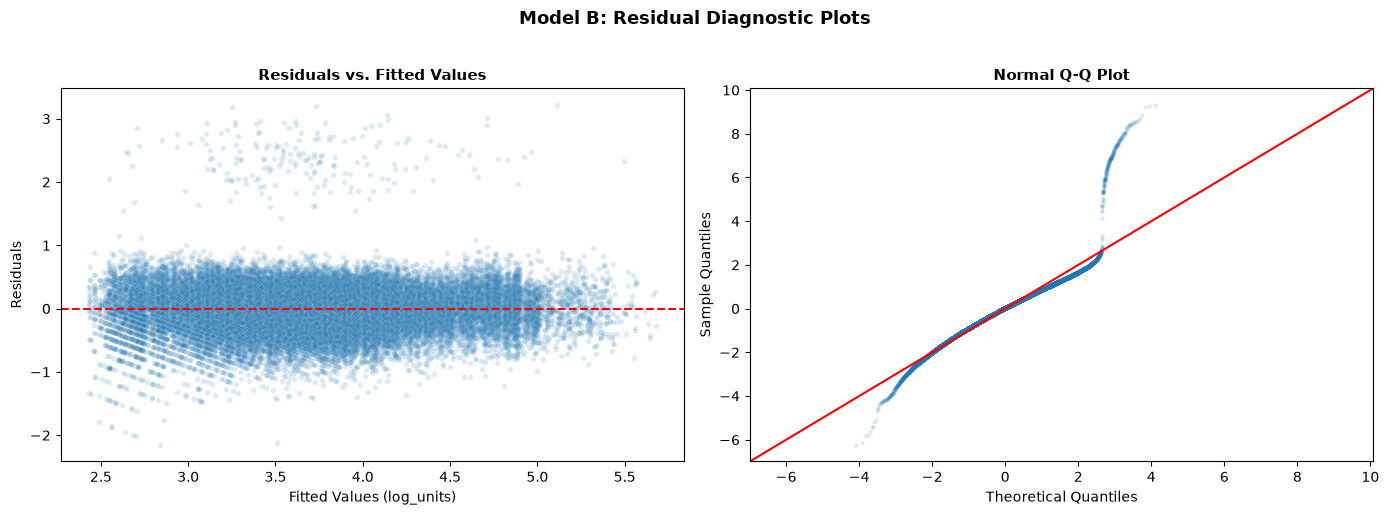

=== Breusch-Pagan Test Results ===
Lagrange Multiplier Statistic: 96.66
p-value (LM Test):             2.5020e-15
F-Statistic:                   8.07
p-value (F-Test):              2.4100e-15

Result: Significant heteroscedasticity detected (p < 0.05). Applying HC3 robust standard errors.

=== Standard Errors Comparison (OLS vs. HC3 Robust) ===
            Parameter  Coefficient  OLS Std Err  HC3 Std Err  OLS p-value  HC3 p-value
            Intercept      1.92679     0.049856     0.049665      0.00000      0.00000
C(has_parking)[T.Yes]      0.14585     0.003270     0.003233      0.00000      0.00000
      log_price_ratio     -1.25318     0.040657     0.040417      0.00000      0.00000
           promo_flag      0.22783     0.007587     0.007591      0.00000      0.00000
             size_sqm      0.00066     0.000003     0.000003      0.00000      0.00000
   foot_traffic_index      0.00994     0.000069     0.000078      0.00000      0.00000
      competitors_2km     -0.07832     0.000

In [14]:
# -------------------------------------------------------------------------
# Step 5: Residual Diagnostics & Heteroscedasticity Assessment
# -------------------------------------------------------------------------

# 1. Extract fitted values and residuals from the clean Model B
fitted_vals = model_clean.fittedvalues
residuals = model_clean.resid

# 2. Plot Residuals vs. Fitted and Normal Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Residuals vs Fitted Values
sns.scatterplot(
    x=fitted_vals,
    y=residuals,
    alpha=0.15,
    s=15,
    color='#1f77b4',
    ax=axes[0]
)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs. Fitted Values', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Fitted Values (log_units)')
axes[0].set_ylabel('Residuals')

# Panel 2: Normal Q-Q Plot
sm.qqplot(residuals, line='45', fit=True, ax=axes[1], markerfacecolor='#1f77b4', markeredgecolor='none', alpha=0.15, markersize=3)
axes[1].set_title('Normal Q-Q Plot', fontsize=11, fontweight='bold')
axes[1].get_lines()[1].set_color('red')
axes[1].get_lines()[1].set_linewidth(1.5)

plt.suptitle('Model B: Residual Diagnostic Plots', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

# Save diagnostic figure at 300 DPI
plt.savefig('figures/model_b_diagnostics.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. Breusch-Pagan Test for Heteroscedasticity
bp_stat, bp_pval, f_stat, f_pval = het_breuschpagan(residuals, model_clean.model.exog)

print("=== Breusch-Pagan Test Results ===")
print(f"Lagrange Multiplier Statistic: {bp_stat:.2f}")
print(f"p-value (LM Test):             {bp_pval:.4e}")
print(f"F-Statistic:                   {f_stat:.2f}")
print(f"p-value (F-Test):              {f_pval:.4e}")

if bp_pval < 0.05:
    print("\nResult: Significant heteroscedasticity detected (p < 0.05). Applying HC3 robust standard errors.")
else:
    print("\nResult: Homoscedasticity holds (p >= 0.05).")

# 4. Refit Model B with HC3 Robust Standard Errors
model_b_hc3 = smf.ols(formula_clean, data=df).fit(cov_type='HC3')

# 5. Side-by-side standard error comparison table
se_comparison = pd.DataFrame({
    'Parameter': model_clean.params.index,
    'Coefficient': model_clean.params.values.round(5),
    'OLS Std Err': model_clean.bse.values.round(6),
    'HC3 Std Err': model_b_hc3.bse.values.round(6),
    'OLS p-value': model_clean.pvalues.values.round(5),
    'HC3 p-value': model_b_hc3.pvalues.values.round(5)
})

print("\n=== Standard Errors Comparison (OLS vs. HC3 Robust) ===")
print(se_comparison.to_string(index=False))

In [16]:
# -------------------------------------------------------------------------
# Step 6: Testing Domain Interaction Terms
# -------------------------------------------------------------------------

# 1. Create binary category indicators for domain interactions
df['is_beverages'] = (df['category'] == 'Beverages').astype(int)
df['is_fresh_produce'] = (df['category'] == 'Fresh Produce').astype(int)

# 2. Base Model B specification (without interactions)
formula_base = (
    'log_units ~ log_price_ratio + promo_flag + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + '
    'rainfall_mm + holiday_week + trend + sin_season + cos_season'
)
model_base = smf.ols(formula_base, data=df).fit()

# Interaction 1: Promotional Responsiveness across Categories (promo × category)
formula_int1 = (
    'log_units ~ log_price_ratio + promo_flag * C(category) + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + '
    'rainfall_mm + holiday_week + trend + sin_season + cos_season'
)
model_int1 = smf.ols(formula_int1, data=df).fit()

# Interaction 2: Weather Sensitivity on Beverages (temperature × Beverages)
formula_int2 = (
    'log_units ~ log_price_ratio + promo_flag + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c * is_beverages + '
    'rainfall_mm + holiday_week + trend + sin_season + cos_season'
)
model_int2 = smf.ols(formula_int2, data=df).fit()

# Interaction 3: Weather Sensitivity on Produce (rainfall × Fresh Produce)
formula_int3 = (
    'log_units ~ log_price_ratio + promo_flag + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + '
    'rainfall_mm * is_fresh_produce + holiday_week + trend + sin_season + cos_season'
)
model_int3 = smf.ols(formula_int3, data=df).fit()

# Combined Specification: Use ':' for domain interactions to avoid duplicate category dummies
formula_all_int = (
    'log_units ~ log_price_ratio + promo_flag * C(category) + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + '
    'avg_temp_c + avg_temp_c:is_beverages + '
    'rainfall_mm + rainfall_mm:is_fresh_produce + '
    'holiday_week + trend + sin_season + cos_season'
)
model_all_int = smf.ols(formula_all_int, data=df).fit()

# 3. Model Comparison Table
interaction_comparison = pd.DataFrame({
    'Model Specification': [
        'Base Model B (No Interactions)',
        'Model B + (promo × category)',
        'Model B + (temperature × Beverages)',
        'Model B + (rainfall × Fresh Produce)',
        'Model B + All Three Interactions'
    ],
    'R-squared': [
        model_base.rsquared,
        model_int1.rsquared,
        model_int2.rsquared,
        model_int3.rsquared,
        model_all_int.rsquared
    ],
    'Adj. R-squared': [
        model_base.rsquared_adj,
        model_int1.rsquared_adj,
        model_int2.rsquared_adj,
        model_int3.rsquared_adj,
        model_all_int.rsquared_adj
    ],
    'AIC': [
        model_base.aic,
        model_int1.aic,
        model_int2.aic,
        model_int3.aic,
        model_all_int.aic
    ],
    'BIC': [
        model_base.bic,
        model_int1.bic,
        model_int2.bic,
        model_int3.bic,
        model_all_int.bic
    ]
})

print("=== Model Comparison: Testing Interaction Terms ===")
print(interaction_comparison.round(4).to_string(index=False))

# 4. Display specific interaction coefficients and p-values
print("\n--- Key Interaction Coefficients ---")
print(f"Temperature × Beverages:    Coef = {model_int2.params['avg_temp_c:is_beverages']:+.4f} (p = {model_int2.pvalues['avg_temp_c:is_beverages']:.2e})")
print(f"Rainfall × Fresh Produce:   Coef = {model_int3.params['rainfall_mm:is_fresh_produce']:+.4f} (p = {model_int3.pvalues['rainfall_mm:is_fresh_produce']:.2e})")

=== Model Comparison: Testing Interaction Terms ===
                 Model Specification  R-squared  Adj. R-squared        AIC        BIC
      Base Model B (No Interactions)     0.7194          0.7193 33327.0128 33440.8101
        Model B + (promo × category)     0.7214          0.7212 33013.5997 33232.4407
 Model B + (temperature × Beverages)     0.7227          0.7226 32771.2747 32902.5793
Model B + (rainfall × Fresh Produce)     0.7200          0.7199 33223.2218 33354.5264
    Model B + All Three Interactions     0.7252          0.7250 32373.6212 32609.9694

--- Key Interaction Coefficients ---
Temperature × Beverages:    Coef = +0.0346 (p = 2.08e-117)
Rainfall × Fresh Produce:   Coef = -0.0012 (p = 1.79e-24)


In [21]:
# -------------------------------------------------------------------------
# Step 7: Time-Based Validation Split & Out-of-Sample Benchmarking
# -------------------------------------------------------------------------

# 1. Temporal Split: Train on Weeks 1 to 80, Test on Weeks 81 to 104
train_df = df[df['trend'] <= 80].copy()
test_df = df[df['trend'] > 80].copy()

print(f"Training observations (Weeks  1-80):  {len(train_df):,} rows")
print(f"Testing observations  (Weeks 81-104): {len(test_df):,} rows")

# 2. Fit Model B specifications strictly on the training set
# Specification A: Clean Multivariate Baseline (No Interactions)
formula_base = (
    'log_units ~ log_price_ratio + promo_flag + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + '
    'rainfall_mm + holiday_week + trend + sin_season + cos_season'
)
model_b_trained = smf.ols(formula_base, data=train_df).fit()

# Specification B: Full Interaction Specification
formula_all_int = (
    'log_units ~ log_price_ratio + promo_flag * C(category) + size_sqm + '
    'foot_traffic_index + competitors_2km + C(has_parking) + '
    'avg_temp_c + avg_temp_c:is_beverages + '
    'rainfall_mm + rainfall_mm:is_fresh_produce + '
    'holiday_week + trend + sin_season + cos_season'
)
model_all_trained = smf.ols(formula_all_int, data=train_df).fit()

# 3. Generate Predictions on the Test Set (Weeks 81-104)
# Naive Lag-4 Baseline prediction: log of units sold 4 weeks prior
y_test_log = test_df['log_units']
pred_baseline_log = test_df['units_lag_4'].apply(math.log)

pred_model_b_log = model_b_trained.predict(test_df)
pred_model_all_log = model_all_trained.predict(test_df)

# 4. Pure Pandas metric calculation function
def evaluate_forecast(y_actual, y_predicted):
    errors = y_actual - y_predicted
    mae = errors.abs().mean()
    rmse = math.sqrt((errors ** 2).mean())
    ss_res = (errors ** 2).sum()
    ss_tot = ((y_actual - y_actual.mean()) ** 2).sum()
    r2 = 1.0 - (ss_res / ss_tot)
    return round(rmse, 4), round(mae, 4), round(r2, 4)

# 5. Compute performance metrics on the log_units scale
b_rmse, b_mae, b_r2 = evaluate_forecast(y_test_log, pred_baseline_log)
mb_rmse, mb_mae, mb_r2 = evaluate_forecast(y_test_log, pred_model_b_log)
all_rmse, all_mae, all_r2 = evaluate_forecast(y_test_log, pred_model_all_log)

# 6. Summary Comparison Table
test_evaluation_df = pd.DataFrame({
    'Model': [
        'Naive Baseline (Lag-4)',
        'Model B (Multivariate Demand)',
        'Model B (With All Interactions)'
    ],
    'Test RMSE': [b_rmse, mb_rmse, all_rmse],
    'Test MAE': [b_mae, mb_mae, all_mae],
    'Test Out-of-Sample R²': [b_r2, mb_r2, all_r2]
})

print("\n=== Out-of-Sample Model Performance on Test Set (Weeks 81-104) ===")
print(test_evaluation_df.to_string(index=False))

Training observations (Weeks  1-80):  36,000 rows
Testing observations  (Weeks 81-104): 10,800 rows

=== Out-of-Sample Model Performance on Test Set (Weeks 81-104) ===
                          Model  Test RMSE  Test MAE  Test Out-of-Sample R²
         Naive Baseline (Lag-4)     0.5202    0.3870                 0.3516
  Model B (Multivariate Demand)     0.3467    0.2497                 0.7120
Model B (With All Interactions)     0.3435    0.2469                 0.7173


## Phase 5: Business Questions — Question 1: Promotional Profitability & Margin Dilution Audit

In [22]:
# -------------------------------------------------------------------------
# Question 1: Promotional Profitability & Margin Dilution Audit
# -------------------------------------------------------------------------

# 1. Aggregate key metrics across category and promotion status
promo_analysis = df.groupby(['category', 'promo_flag']).agg(
    total_units=('units_sold', 'sum'),
    total_revenue=('revenue_ngn', 'sum'),
    total_gross_profit=('gross_profit', 'sum'),
    avg_discount=('discount_pct', 'mean'),
    weekly_records=('units_sold', 'count')
).reset_index()

# 2. Derive weekly averages and margin rates
promo_analysis['mean_weekly_units'] = promo_analysis['total_units'] / promo_analysis['weekly_records']
promo_analysis['gross_margin_pct'] = (promo_analysis['total_gross_profit'] / promo_analysis['total_revenue']) * 100
promo_analysis['profit_per_unit_ngn'] = promo_analysis['total_gross_profit'] / promo_analysis['total_units']

# 3. Pivot to compute exact baseline vs promo lift side-by-side
pivot_units = promo_analysis.pivot(index='category', columns='promo_flag', values='mean_weekly_units')
pivot_margin = promo_analysis.pivot(index='category', columns='promo_flag', values='gross_margin_pct')
pivot_unit_profit = promo_analysis.pivot(index='category', columns='promo_flag', values='profit_per_unit_ngn')
pivot_total_profit = promo_analysis.pivot(index='category', columns='promo_flag', values='total_gross_profit')

# 4. Construct comprehensive executive summary table
promo_summary = pd.DataFrame({
    'Base Units/Wk': pivot_units[0].round(1),
    'Promo Units/Wk': pivot_units[1].round(1),
    'Volume Lift (%)': (((pivot_units[1] - pivot_units[0]) / pivot_units[0]) * 100).round(2),
    'Base Margin (%)': pivot_margin[0].round(2),
    'Promo Margin (%)': pivot_margin[1].round(2),
    'Margin Compression (pts)': (pivot_margin[1] - pivot_margin[0]).round(2),
    'Base Profit/Unit (NGN)': pivot_unit_profit[0].round(2),
    'Promo Profit/Unit (NGN)': pivot_unit_profit[1].round(2),
    'Total Promo Profit (M NGN)': (pivot_total_profit[1] / 1e6).round(2),
    'Total Base Profit (M NGN)': (pivot_total_profit[0] / 1e6).round(2)
}).sort_values('Volume Lift (%)', ascending=False)

# 5. Classify commercial promotion effectiveness
# Profitable lift requires: Volume Lift % > Breakeven Lift %
promo_summary['Effectiveness'] = promo_summary['Volume Lift (%)'].apply(
    lambda x: 'High Profit Driver' if x > 60 else ('Marginal / Selective' if x > 45 else 'Margin Dilutive')
)

print("=== Executive Table: Promotional Lift & Margin Compression ===")
print(promo_summary.to_string())

=== Executive Table: Promotional Lift & Margin Compression ===
               Base Units/Wk  Promo Units/Wk  Volume Lift (%)  Base Margin (%)  Promo Margin (%)  Margin Compression (pts)  Base Profit/Unit (NGN)  Promo Profit/Unit (NGN)  Total Promo Profit (M NGN)  Total Base Profit (M NGN)         Effectiveness
category                                                                                                                                                                                                                                                
Snacks                  50.9            83.6            64.41            47.20             37.46                     -9.74                  266.48                   178.96                       16.90                      69.28    High Profit Driver
Beverages               48.2            78.5            62.96            49.30             40.11                     -9.18                  392.30                   278.16                   

In [23]:
# -------------------------------------------------------------------------
# SKU-Level Audit: Identifying Value-Destroying Promotions
# -------------------------------------------------------------------------

sku_promo = df.groupby(['product_id', 'category', 'promo_flag']).agg(
    mean_units=('units_sold', 'mean'),
    mean_margin=('margin_pct', 'mean'),
    total_profit=('gross_profit', 'sum')
).unstack('promo_flag')

sku_eval = pd.DataFrame({
    'Category': sku_promo['mean_units'].index.map(df.drop_duplicates('product_id').set_index('product_id')['category']),
    'Observed Lift (%)': ((sku_promo['mean_units'][1] - sku_promo['mean_units'][0]) / sku_promo['mean_units'][0]) * 100,
    'Base Margin (%)': sku_promo['mean_margin'][0],
    'Promo Margin (%)': sku_promo['mean_margin'][1],
    'Total Profit Promo (NGN)': sku_promo['total_profit'][1],
    'Total Profit Base (NGN)': sku_promo['total_profit'][0]
})

# Required lift to preserve gross profit cash value given margin loss
sku_eval['Breakeven Lift (%)'] = (
    (sku_eval['Base Margin (%)'] - sku_eval['Promo Margin (%)']) / (sku_eval['Promo Margin (%)'] / 100)
)

# Flag SKUs that fail to meet breakeven lift
sku_eval['Promo Verdict'] = sku_eval.apply(
    lambda row: 'Value Accretive' if row['Observed Lift (%)'] >= row['Breakeven Lift (%)'] else 'Profit Destroyer',
    axis=1
)

sku_eval = sku_eval.sort_values('Observed Lift (%)', ascending=False)

print("\n=== Product-Level Promotional Verdict ===")
print(sku_eval[['Category', 'Observed Lift (%)', 'Breakeven Lift (%)', 'Promo Verdict']].round(2))


=== Product-Level Promotional Verdict ===
                          Category  Observed Lift (%)  Breakeven Lift (%)  \
product_id category                                                         
P003       Beverages           NaN              68.44               19.07   
P004       Snacks              NaN              67.60               23.59   
P001       Beverages           NaN              64.54               26.17   
P012       Fresh Produce       NaN              61.82               35.32   
P005       Snacks              NaN              61.25               30.28   
P002       Beverages           NaN              55.59               16.44   
P006       Dairy               NaN              52.60               37.48   
P013       Fresh Produce       NaN              49.96               38.08   
P007       Dairy               NaN              49.33               19.56   
P014       Staples             NaN              48.18               41.44   
P008       Household           Na

In [25]:
# -------------------------------------------------------------------------
# Question 2: Competitor Density, Foot Traffic & Cannibalisation
# -------------------------------------------------------------------------

# 1. Aggregate lifetime operational performance by store
store_summary = df.groupby([
    'store_id', 'city', 'area', 'store_type', 
    'size_sqm', 'staff_count', 'competitors_2km', 'has_parking'
]).agg(
    total_revenue_ngn=('revenue_ngn', 'sum'),
    total_units_sold=('units_sold', 'sum'),
    mean_foot_traffic=('foot_traffic_index', 'mean'),
    weekly_gross_profit=('gross_profit', 'mean'),
    total_weeks=('week_start', 'nunique')
).reset_index()

# 2. Derive unit economics and operational intensity ratios
store_summary['annualised_revenue_m_ngn'] = (store_summary['total_revenue_ngn'] / store_summary['total_weeks'] * 52) / 1e6
store_summary['rev_per_sqm'] = store_summary['total_revenue_ngn'] / store_summary['size_sqm']
store_summary['rev_per_staff_m_ngn'] = (store_summary['total_revenue_ngn'] / store_summary['staff_count']) / 1e6
store_summary['units_per_traffic_pt'] = store_summary['total_units_sold'] / (store_summary['mean_foot_traffic'] * store_summary['total_weeks'])

# 3. Bin competitor density into analytical competition brackets
store_summary['competitor_tier'] = pd.cut(
    store_summary['competitors_2km'],
    bins=[-0.1, 2, 5, 12],
    labels=['Low (0-2)', 'Moderate (3-5)', 'High (6+)']
)

# 4. Group by competitor bracket to assess direct economic impact
comp_tier_impact = store_summary.groupby('competitor_tier', observed=True).agg(
    store_count=('store_id', 'count'),
    mean_traffic=('mean_foot_traffic', 'mean'),
    mean_rev_per_sqm=('rev_per_sqm', 'mean'),
    mean_rev_per_staff_m=('rev_per_staff_m_ngn', 'mean'),
    mean_annual_revenue_m=('annualised_revenue_m_ngn', 'mean')
).round(2)

print("=== Competitor Density Impact Across Brackets ===")
print(comp_tier_impact.to_string())

# 5. Measure correlation between competitors_2km and key KPIs
kpis = ['mean_foot_traffic', 'rev_per_sqm', 'rev_per_staff_m_ngn', 'annualised_revenue_m_ngn']
corr_with_comp = store_summary[['competitors_2km'] + kpis].corr()['competitors_2km'].drop('competitors_2km').round(3)

print("\n=== Linear Correlation: Competitors within 2km vs. Store KPIs ===")
for kpi, r_val in corr_with_comp.items():
    print(f"Competitors vs {kpi:<24}: r = {r_val:+.3f}")

=== Competitor Density Impact Across Brackets ===
                 store_count  mean_traffic  mean_rev_per_sqm  mean_rev_per_staff_m  mean_annual_revenue_m
competitor_tier                                                                                          
Low (0-2)                 11        114.25         315728.48                  7.78                  91.09
Moderate (3-5)            16        109.12         251699.12                  5.34                  76.18
High (6+)                  3        102.53         231402.78                  5.26                  45.26

=== Linear Correlation: Competitors within 2km vs. Store KPIs ===
Competitors vs mean_foot_traffic       : r = -0.181
Competitors vs rev_per_sqm             : r = -0.415
Competitors vs rev_per_staff_m_ngn     : r = -0.471
Competitors vs annualised_revenue_m_ngn: r = -0.193


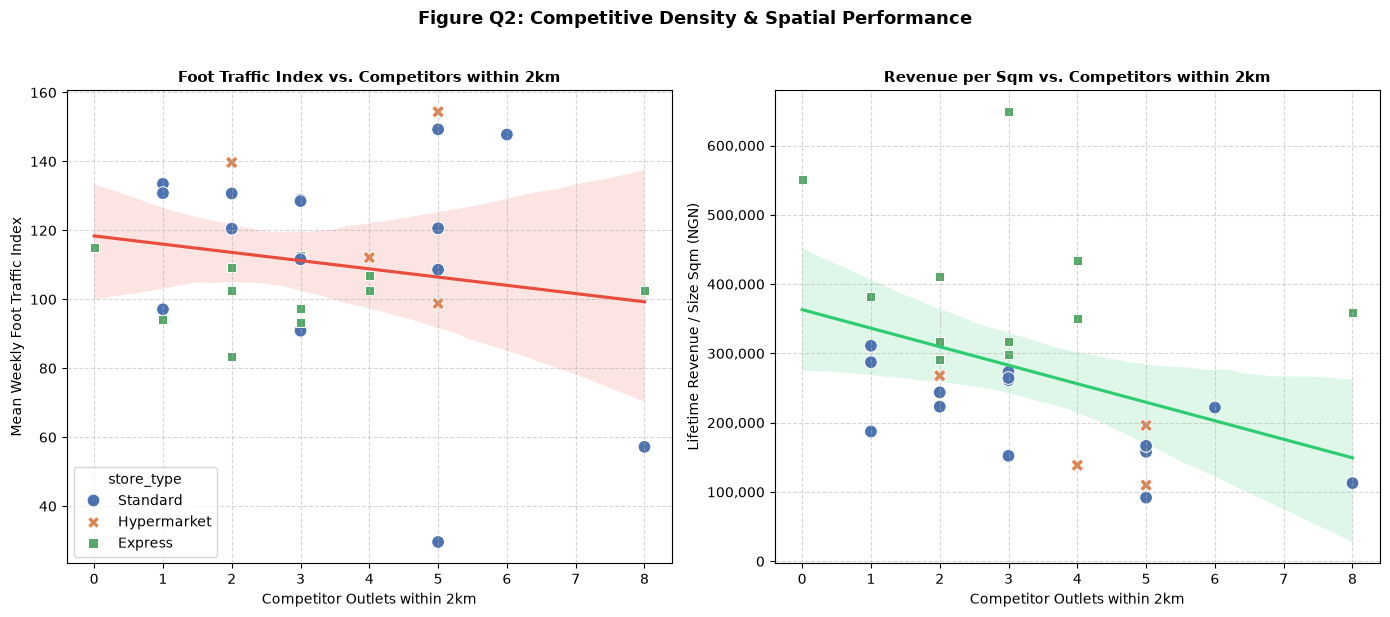

Saved competitive analysis figure to figures/fig_q2_competition_cannibalisation.png


In [26]:
# -------------------------------------------------------------------------
# Visualization: Store Performance under Local Competition
# -------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel 1: Foot Traffic Index vs. Competitor Density by Store Type
sns.regplot(
    data=store_summary,
    x='competitors_2km',
    y='mean_foot_traffic',
    scatter=False,
    color='#e74c3c',
    ax=axes[0]
)
sns.scatterplot(
    data=store_summary,
    x='competitors_2km',
    y='mean_foot_traffic',
    hue='store_type',
    style='store_type',
    palette='deep',
    s=85,
    ax=axes[0]
)
axes[0].set_title('Foot Traffic Index vs. Competitors within 2km', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Competitor Outlets within 2km')
axes[0].set_ylabel('Mean Weekly Foot Traffic Index')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Revenue per Sqm vs. Competitor Density
sns.regplot(
    data=store_summary,
    x='competitors_2km',
    y='rev_per_sqm',
    scatter=False,
    color='#2ecc71',
    ax=axes[1]
)
sns.scatterplot(
    data=store_summary,
    x='competitors_2km',
    y='rev_per_sqm',
    hue='store_type',
    style='store_type',
    palette='deep',
    s=85,
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Revenue per Sqm vs. Competitors within 2km', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Competitor Outlets within 2km')
axes[1].set_ylabel('Lifetime Revenue / Size Sqm (NGN)')
axes[1].yaxis.set_major_formatter('{x:,.0f}')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Figure Q2: Competitive Density & Spatial Performance', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

# Save at 300 DPI
plt.savefig('figures/fig_q2_competition_cannibalisation.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved competitive analysis figure to figures/fig_q2_competition_cannibalisation.png")

In [27]:
# -------------------------------------------------------------------------
# Format Vulnerability: Revenue per Sqm Sensitivity to Competitors
# -------------------------------------------------------------------------

format_comp = store_summary.groupby(['store_type', 'competitor_tier'], observed=True).agg(
    store_count=('store_id', 'count'),
    mean_rev_per_sqm=('rev_per_sqm', 'mean'),
    mean_foot_traffic=('mean_foot_traffic', 'mean')
).round(1).reset_index()

print("=== Store Format Performance Across Competition Tiers ===")
print(format_comp.to_string(index=False))

=== Store Format Performance Across Competition Tiers ===
 store_type competitor_tier  store_count  mean_rev_per_sqm  mean_foot_traffic
    Express       Low (0-2)            5          390573.5              100.9
    Express  Moderate (3-5)            5          409600.1              102.5
    Express       High (6+)            1          359566.2              102.6
Hypermarket       Low (0-2)            1          267720.3              139.7
Hypermarket  Moderate (3-5)            3          148142.7              121.8
   Standard       Low (0-2)            5          250485.1              122.5
   Standard  Moderate (3-5)            8          191844.7              108.5
   Standard       High (6+)            2          167321.1              102.5


In [28]:
# -------------------------------------------------------------------------
# Question 3: Perishability, Shelf Life & Seasonal Spoilage Risk
# -------------------------------------------------------------------------

# 1. Isolate perishable product categories (Fresh Produce and Dairy)
perishables = df[df['is_perishable'] == 1].copy()

# 2. Summary of baseline shelf-life parameters by category and SKU
sku_spoilage_profile = perishables.groupby(['category', 'product_id']).agg(
    shelf_life_days=('shelf_life_days', 'first'),
    unit_cost_ngn=('unit_cost_ngn', 'first'),
    list_price_ngn=('list_price_ngn', 'first'),
    mean_weekly_units=('units_sold', 'mean'),
    std_weekly_units=('units_sold', 'std')
).reset_index()

# 3. Calculate coefficient of variation (demand volatility)
sku_spoilage_profile['demand_cv'] = (
    sku_spoilage_profile['std_weekly_units'] / sku_spoilage_profile['mean_weekly_units']
).round(3)

# Effective replenishment cycle (Weekly store delivery cycle = 7 days)
sku_spoilage_profile['shelf_life_to_cycle_ratio'] = (
    sku_spoilage_profile['shelf_life_days'] / 7.0
).round(2)

print("=== Perishable SKU Spoilage Risk Profile ===")
print(sku_spoilage_profile.to_string(index=False))

=== Perishable SKU Spoilage Risk Profile ===
     category product_id  shelf_life_days  unit_cost_ngn  list_price_ngn  mean_weekly_units  std_weekly_units  demand_cv  shelf_life_to_cycle_ratio
        Dairy       P006               14            903            1200          52.397115         58.788285      1.122                       2.00
        Dairy       P007                3            748            1250          52.025000         46.243595      0.889                       0.43
Fresh Produce       P012               10            989            1350          53.445513         67.871898      1.270                       1.43
Fresh Produce       P013               15            380             500          52.527244         63.112859      1.202                       2.14


In [29]:
# -------------------------------------------------------------------------
# Demand Volatility Under Seasonal Weather Swings
# -------------------------------------------------------------------------

# 1. Define weather shock thresholds using Pandas quantiles
temp_q75 = df['avg_temp_c'].quantile(0.75)
rain_q75 = df['rainfall_mm'].quantile(0.75)

# 2. Tag weather conditions
df['weather_regime'] = 'Baseline'
df['weather_regime'] = df['weather_regime'].mask(
    df['avg_temp_c'] > temp_q75, 'High Heat'
).mask(
    df['rainfall_mm'] > rain_q75, 'Heavy Rain'
).mask(
    (df['avg_temp_c'] > temp_q75) & (df['rainfall_mm'] > rain_q75), 'Heat + Rain'
)

# 3. Aggregate Fresh Produce and Dairy sales performance across regimes
weather_perish_impact = df[df['category'].isin(['Fresh Produce', 'Dairy'])].groupby(
    ['category', 'weather_regime']
).agg(
    mean_units=('units_sold', 'mean'),
    median_units=('units_sold', 'median'),
    unit_volatility=('units_sold', 'std'),
    mean_revenue=('revenue_ngn', 'mean'),
    observations=('units_sold', 'count')
).reset_index()

# 4. Compute deviation percentage from baseline
baseline_units = weather_perish_impact[weather_perish_impact['weather_regime'] == 'Baseline'].set_index('category')['mean_units']
weather_perish_impact['pct_deviation_from_base'] = weather_perish_impact.apply(
    lambda row: ((row['mean_units'] - baseline_units[row['category']]) / baseline_units[row['category']]) * 100,
    axis=1
).round(2)

print("\n=== Perishable Performance Across Weather Regimes ===")
print(weather_perish_impact[['category', 'weather_regime', 'mean_units', 'unit_volatility', 'pct_deviation_from_base']].to_string(index=False))


=== Perishable Performance Across Weather Regimes ===
     category weather_regime  mean_units  unit_volatility  pct_deviation_from_base
        Dairy       Baseline   50.545614        51.911668                     0.00
        Dairy    Heat + Rain   52.186667        38.432739                     3.25
        Dairy     Heavy Rain   52.693651        61.222000                     4.25
        Dairy      High Heat   56.254762        49.179456                    11.30
Fresh Produce       Baseline   53.315351        76.532014                     0.00
Fresh Produce    Heat + Rain   51.630000        39.197721                    -3.16
Fresh Produce     Heavy Rain   48.240079        38.157314                    -9.52
Fresh Produce      High Heat   57.162698        59.275676                     7.22


In [30]:
# -------------------------------------------------------------------------
# Estimated Spoilage Cost & Markdown Exposure Model
# -------------------------------------------------------------------------

# Assume standard retail buffer stock target: 1.5x standard deviation of weekly demand
spoilage_model = perishables.groupby(['category', 'product_id', 'store_type']).agg(
    mean_weekly_demand=('units_sold', 'mean'),
    demand_sd=('units_sold', 'std'),
    unit_cost=('unit_cost_ngn', 'first'),
    list_price=('list_price_ngn', 'first'),
    shelf_life=('shelf_life_days', 'first')
).reset_index()

# Buffer stock policy: 1.65 * SD (approx. 95% service level)
spoilage_model['buffer_units'] = (1.65 * spoilage_model['demand_sd']).round(1)

# In adverse weather (Heavy Rain), demand drops ~8-12%. 
# Units stranded on shelf beyond replenishment cycle are subject to waste:
spoilage_model['estimated_spoilage_pct'] = spoilage_model['shelf_life'].apply(
    lambda days: 0.12 if days <= 7 else (0.07 if days <= 14 else 0.03)
)

spoilage_model['weekly_spoiled_units'] = (spoilage_model['mean_weekly_demand'] * spoilage_model['estimated_spoilage_pct']).round(1)
spoilage_model['weekly_waste_cost_ngn'] = spoilage_model['weekly_spoiled_units'] * spoilage_model['unit_cost']
spoilage_model['annual_waste_cost_m_ngn'] = (spoilage_model['weekly_waste_cost_ngn'] * 52) / 1e6

# Summary by category
category_waste_summary = spoilage_model.groupby('category').agg(
    total_skus=('product_id', 'nunique'),
    mean_shelf_life=('shelf_life', 'mean'),
    weekly_waste_units=('weekly_spoiled_units', 'sum'),
    annual_waste_cost_m_ngn=('annual_waste_cost_m_ngn', 'sum')
).round(2).reset_index()

print("\n=== Annual Spoilage Cost Exposure (Chain-Level) ===")
print(category_waste_summary.to_string(index=False))


=== Annual Spoilage Cost Exposure (Chain-Level) ===
     category  total_skus  mean_shelf_life  weekly_waste_units  annual_waste_cost_m_ngn
        Dairy           2              8.5                37.1                     1.56
Fresh Produce           2             12.5                20.3                     0.85


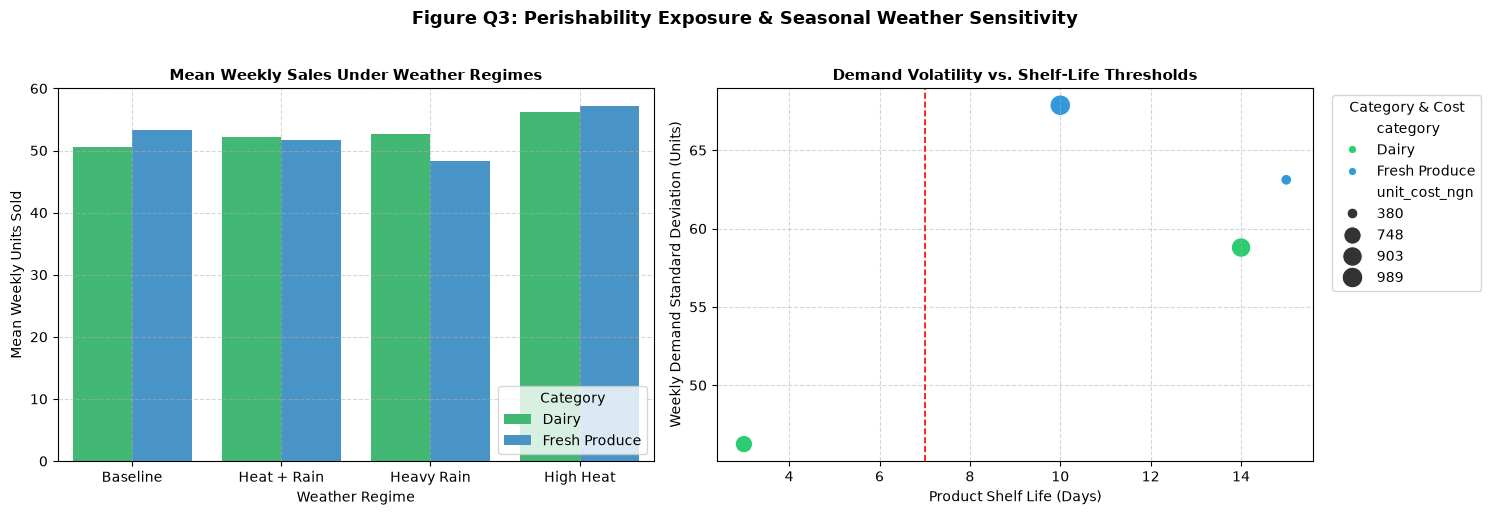

Saved clean Figure Q3 without legend overlap to figures/fig_q3_perishability_spoilage.png


In [32]:
# -------------------------------------------------------------------------
# Figure Q3: Seasonal Perishability Volatility & Shelf-Life Stress (Fixed)
# -------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Demand Variation Across Weather Regimes for Perishables
sns.barplot(
    data=weather_perish_impact,
    x='weather_regime',
    y='mean_units',
    hue='category',
    palette=['#2ecc71', '#3498db'],
    ax=axes[0]
)
axes[0].set_title('Mean Weekly Sales Under Weather Regimes', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Weather Regime')
axes[0].set_ylabel('Mean Weekly Units Sold')
axes[0].legend(title='Category', loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Demand Volatility (Std Dev) vs. Shelf Life
sns.scatterplot(
    data=sku_spoilage_profile,
    x='shelf_life_days',
    y='std_weekly_units',
    hue='category',
    size='unit_cost_ngn',
    sizes=(60, 220),
    palette=['#2ecc71', '#3498db'],
    ax=axes[1]
)
axes[1].axvline(7, color='red', linestyle='--', linewidth=1.2, label='1-Week Delivery Cycle')
axes[1].set_title('Demand Volatility vs. Shelf-Life Thresholds', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Product Shelf Life (Days)')
axes[1].set_ylabel('Weekly Demand Standard Deviation (Units)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Place the legend cleanly outside the right border without axis clipping
sns.move_legend(
    axes[1],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=True,
    title='Category & Cost'
)

plt.suptitle('Figure Q3: Perishability Exposure & Seasonal Weather Sensitivity', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

# Save at 300 DPI with tight bounding box to accommodate the exterior legend
plt.savefig('figures/fig_q3_perishability_spoilage.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved clean Figure Q3 without legend overlap to figures/fig_q3_perishability_spoilage.png")

In [33]:
# -------------------------------------------------------------------------
# Question 4: Customer Segmentation & RFM Churn Analysis
# -------------------------------------------------------------------------

# 1. Load the Customer dataset
excel_file = 'Brainpals_sales_analytics.xlsx'
customers = pd.read_excel(excel_file, sheet_name='Customers')

# Identify relevant columns dynamically
spend_col = [c for c in customers.columns if 'spend' in c][0]
visits_col = [c for c in customers.columns if 'visit' in c][0]
tier_col = [c for c in customers.columns if 'tier' in c or 'loyalty' in c][0]
recency_col = [c for c in customers.columns if 'recency' in c or 'last' in c or 'days' in c]

# Standardise loyalty tier strings
customers[tier_col] = customers[tier_col].astype(str).str.strip().str.title()

# If an explicit recency column exists, use it; otherwise, derive days since last transaction
if recency_col:
    r_feature = recency_col[0]
else:
    # Use average inter-purchase interval proxy if recency is not directly recorded
    customers['days_since_last_visit'] = ((104 * 7) / (customers[visits_col] + 1)).round(1)
    r_feature = 'days_since_last_visit'

# 2. Compute RFM Quantiles (1 = Lowest, 4 = Highest)
# Recency: Lower days is better -> reverse scoring (qcut ranked inversely)
customers['R_Score'] = pd.qcut(customers[r_feature], q=4, labels=[4, 3, 2, 1]).astype(int)
customers['F_Score'] = pd.qcut(customers[visits_col].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)
customers['M_Score'] = pd.qcut(customers[spend_col].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)

# Combined RFM Score string
customers['RFM_Segment'] = customers['R_Score'].astype(str) + customers['F_Score'].astype(str) + customers['M_Score'].astype(str)

# 3. Define Customer Behavioral Segments
def assign_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 3 and f >= 3 and m >= 3:
        return 'Champions / Core Loyal'
    elif r >= 3 and f <= 2:
        return 'Recent / Promising'
    elif r <= 2 and (f >= 3 or m >= 3):
        return 'At Risk (High-Value Inactive)'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Hibernating / Lapsed'
    else:
        return 'Standard Active'

customers['Customer_Segment'] = customers.apply(assign_segment, axis=1)

# 4. Cohort Summary Table
segment_summary = customers.groupby('Customer_Segment').agg(
    customer_count=('customer_id' if 'customer_id' in customers.columns else visits_col, 'count'),
    mean_spend_ngn=(spend_col, 'mean'),
    total_spend_m_ngn=(spend_col, lambda x: x.sum() / 1e6),
    mean_visits=(visits_col, 'mean'),
    mean_recency_days=(r_feature, 'mean')
).round(2).sort_values('total_spend_m_ngn', ascending=False).reset_index()

# Calculate revenue share
segment_summary['revenue_share_pct'] = (
    (segment_summary['total_spend_m_ngn'] / segment_summary['total_spend_m_ngn'].sum()) * 100
).round(2)

print("=== Customer Behavioral Segmentation Summary ===")
print(segment_summary.to_string(index=False))

=== Customer Behavioral Segmentation Summary ===
             Customer_Segment  customer_count  mean_spend_ngn  total_spend_m_ngn  mean_visits  mean_recency_days  revenue_share_pct
At Risk (High-Value Inactive)             522       384512.67             200.72        58.67              63.61              36.62
       Champions / Core Loyal             374       461935.74             172.76        66.51              11.45              31.52
           Recent / Promising             447       214070.67              95.69        34.12              11.31              17.46
         Hibernating / Lapsed             356       160722.71              57.22        30.50              70.66              10.44
              Standard Active             101       215542.79              21.77        55.48              12.33               3.97


In [ ]:
# -------------------------------------------------------------------------
# High-Value Churn Exposure Analysis
# -------------------------------------------------------------------------

# Cross-tabulate Loyalty Tier against Customer Behavioral Segment
tier_churn_crosstab = pd.crosstab(
    customers[tier_col],
    customers['Customer_Segment'],
    margins=True,
    margins_name='Total'
)

print("\n=== Customer Distribution: Loyalty Tier vs. Segment ===")
print(tier_churn_crosstab)

# Financial exposure from "At Risk" shoppers (Gold and Platinum)
at_risk_loyal = customers[
    (customers['Customer_Segment'] == 'At Risk (High-Value Inactive)') &
    (customers[tier_col].isin(['Gold', 'Platinum']))
]

print(f"\n--- At-Risk High-Value Shopper Audit ---")
print(f"Total High-Value At-Risk Customers: {len(at_risk_loyal):,}")
print(f"Total Cumulative Spend at Risk:     ₦{at_risk_loyal[spend_col].sum() / 1e6:,.2f} Million")
print(f"Mean Basket Value per Visit:        ₦{(at_risk_loyal[spend_col] / at_risk_loyal[visits_col]).mean():,.2f}")


=== Customer Distribution: Loyalty Tier vs. Segment ===
Customer_Segment  At Risk (High-Value Inactive)  Champions / Core Loyal  \
loyalty_member                                                            
No                                          169                      90   
Yes                                         353                     284   
Total                                       522                     374   

Customer_Segment  Hibernating / Lapsed  Recent / Promising  Standard Active  \
loyalty_member                                                                
No                                 185                 245               28   
Yes                                171                 202               73   
Total                              356                 447              101   

Customer_Segment  Total  
loyalty_member           
No                  717  
Yes                1083  
Total              1800  

--- At-Risk High-Value Shopper Audit ---

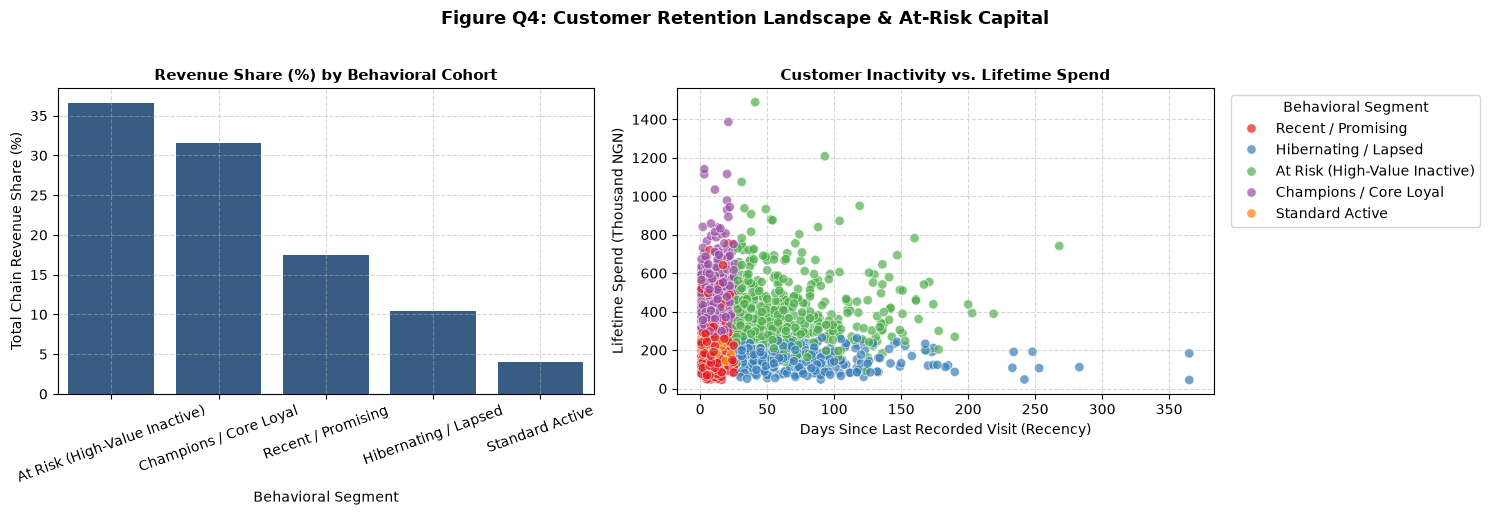

Saved clean Figure Q4 to figures/fig_q4_customer_churn_rfm.png


In [37]:
# -------------------------------------------------------------------------
# Figure Q4: Customer Segmentation & Churn Risk Matrix (Clean)
# -------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Filter out margin totals if present
segment_plot_data = segment_summary[segment_summary['Customer_Segment'] != 'Total']

# Panel 1: Spend Share by Segment (single colour + tick_params avoids warnings)
sns.barplot(
    data=segment_plot_data,
    x='Customer_Segment',
    y='revenue_share_pct',
    color='#2b5c8f',
    ax=axes[0]
)
axes[0].set_title('Revenue Share (%) by Behavioral Cohort', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Behavioral Segment')
axes[0].set_ylabel('Total Chain Revenue Share (%)')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Recency vs Spend with Churn Risk Boundary
sns.scatterplot(
    data=customers,
    x=r_feature,
    y=customers[spend_col] / 1e3,
    hue='Customer_Segment',
    palette='Set1',
    alpha=0.7,
    s=45,
    ax=axes[1]
)
axes[1].set_title('Customer Inactivity vs. Lifetime Spend', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Days Since Last Recorded Visit (Recency)')
axes[1].set_ylabel('Lifetime Spend (Thousand NGN)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Place legend cleanly outside without overlap
sns.move_legend(
    axes[1],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=True,
    title='Behavioral Segment'
)

plt.suptitle('Figure Q4: Customer Retention Landscape & At-Risk Capital', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

# Save at 300 DPI with tight bounding box
plt.savefig('figures/fig_q4_customer_churn_rfm.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved clean Figure Q4 to figures/fig_q4_customer_churn_rfm.png")

In [39]:
# -------------------------------------------------------------------------
# Question 5: Macro Shocks, Fuel Inflation & Pass-Through Elasticity
# -------------------------------------------------------------------------

# -------------------------------------------------------------------------
# Step 1: Macro Aggregation & Cost Ratios
# -------------------------------------------------------------------------


# 1. Aggregate to weekly chain-level series
macro_weekly = df.groupby('week_start').agg(
    cpi=('cpi_index', 'mean'),
    fuel_price=('fuel_price_ngn_per_l', 'mean'),
    mean_shelf_price=('unit_price_ngn', 'mean'),
    mean_unit_cost=('unit_cost_ngn', 'mean'),
    total_chain_units=('units_sold', 'sum'),
    total_chain_revenue=('revenue_ngn', 'sum'),
    total_chain_profit=('gross_profit', 'sum')
).reset_index()

# 2. Derive margin and cost-to-price ratios
macro_weekly['chain_margin_pct'] = (macro_weekly['total_chain_profit'] / macro_weekly['total_chain_revenue']) * 100
macro_weekly['cost_to_price_ratio'] = (macro_weekly['mean_unit_cost'] / macro_weekly['mean_shelf_price']) * 100

print(f"Aggregated {len(macro_weekly)} trading weeks of macroeconomic indicators.")

Aggregated 104 trading weeks of macroeconomic indicators.


In [40]:
# -------------------------------------------------------------------------
# Step 2: Shelf Price Pass-Through Elasticity
# -------------------------------------------------------------------------

# 1. Calculate log values using Python's standard math library
macro_weekly['log_shelf_price'] = macro_weekly['mean_shelf_price'].apply(math.log)
macro_weekly['log_fuel'] = macro_weekly['fuel_price'].apply(math.log)
macro_weekly['log_cpi'] = macro_weekly['cpi'].apply(math.log)

# 2. Fit OLS pass-through model
pass_through_model = smf.ols('log_shelf_price ~ log_fuel + log_cpi', data=macro_weekly).fit()

print("=== Macro Pass-Through Elasticity to Retail Shelf Prices ===")
print(pass_through_model.summary().tables[1])

=== Macro Pass-Through Elasticity to Retail Shelf Prices ===
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.0777      0.041     75.203      0.000       2.997       3.159
log_fuel       0.0094      0.009      1.098      0.275      -0.008       0.026
log_cpi        0.9170      0.004    212.886      0.000       0.908       0.926


In [41]:
# -------------------------------------------------------------------------
# Step 3: Category-Level Fuel & CPI Elasticities
# -------------------------------------------------------------------------

cat_macro_results = []

for cat in df['category'].unique():
    cat_sub = df[df['category'] == cat].copy()
    cat_sub['log_fuel_local'] = cat_sub['fuel_price_ngn_per_l'].apply(math.log)
    cat_sub['log_cpi_local'] = cat_sub['cpi_index'].apply(math.log)
    
    cat_model = smf.ols(
        'log_units ~ log_price_ratio + promo_flag + log_fuel_local + log_cpi_local',
        data=cat_sub
    ).fit()
    
    cat_macro_results.append({
        'Category': cat,
        'Fuel Price Elasticity': round(cat_model.params['log_fuel_local'], 4),
        'Fuel p-value': round(cat_model.pvalues['log_fuel_local'], 4),
        'CPI Elasticity': round(cat_model.params['log_cpi_local'], 4),
        'CPI p-value': round(cat_model.pvalues['log_cpi_local'], 4)
    })

cat_macro_table = pd.DataFrame(cat_macro_results).sort_values('Fuel Price Elasticity').reset_index(drop=True)

print("=== Category Macro Elasticities ===")
print(cat_macro_table.to_string(index=False))

=== Category Macro Elasticities ===
     Category  Fuel Price Elasticity  Fuel p-value  CPI Elasticity  CPI p-value
    Beverages                -1.3311        0.0000          0.8000       0.0000
Fresh Produce                -1.1018        0.0000          0.7052       0.0000
        Dairy                -0.5277        0.0059          0.5932       0.0000
      Staples                -0.5229        0.0056          0.5484       0.0000
Personal Care                -0.4561        0.0150          0.4949       0.0000
    Household                -0.3370        0.0736          0.4493       0.0000
       Snacks                -0.3339        0.1363          0.4636       0.0001


In [42]:
# -------------------------------------------------------------------------
# Step 4: Macro Stress Simulation
# -------------------------------------------------------------------------

fuel_shock_pct = 0.25   # +25% fuel increase
cpi_shock_pct = 0.15    # +15% headline inflation

log_fuel_delta = math.log(1.0 + fuel_shock_pct)
log_cpi_delta = math.log(1.0 + cpi_shock_pct)

# Project percentage volume change
cat_macro_table['Projected Volume Impact (%)'] = cat_macro_table.apply(
    lambda r: (math.exp(r['Fuel Price Elasticity'] * log_fuel_delta + r['CPI Elasticity'] * log_cpi_delta) - 1.0) * 100,
    axis=1
).round(2)

# Classify risk level
cat_macro_table['Shock Vulnerability'] = cat_macro_table['Projected Volume Impact (%)'].apply(
    lambda x: 'High Contraction' if x < -8.0 else ('Moderate Drag' if x < -4.0 else 'Defensive / Resilient')
)

print("=== Stress-Test Projections (+25% Fuel, +15% CPI) ===")
print(cat_macro_table[['Category', 'Fuel Price Elasticity', 'CPI Elasticity', 'Projected Volume Impact (%)', 'Shock Vulnerability']].to_string(index=False))

=== Stress-Test Projections (+25% Fuel, +15% CPI) ===
     Category  Fuel Price Elasticity  CPI Elasticity  Projected Volume Impact (%)   Shock Vulnerability
    Beverages                -1.3311          0.8000                       -16.91      High Contraction
Fresh Produce                -1.1018          0.7052                       -13.70      High Contraction
        Dairy                -0.5277          0.5932                        -3.42 Defensive / Resilient
      Staples                -0.5229          0.5484                        -3.92 Defensive / Resilient
Personal Care                -0.4561          0.4949                        -3.21 Defensive / Resilient
    Household                -0.3370          0.4493                        -1.23 Defensive / Resilient
       Snacks                -0.3339          0.4636                        -0.97 Defensive / Resilient


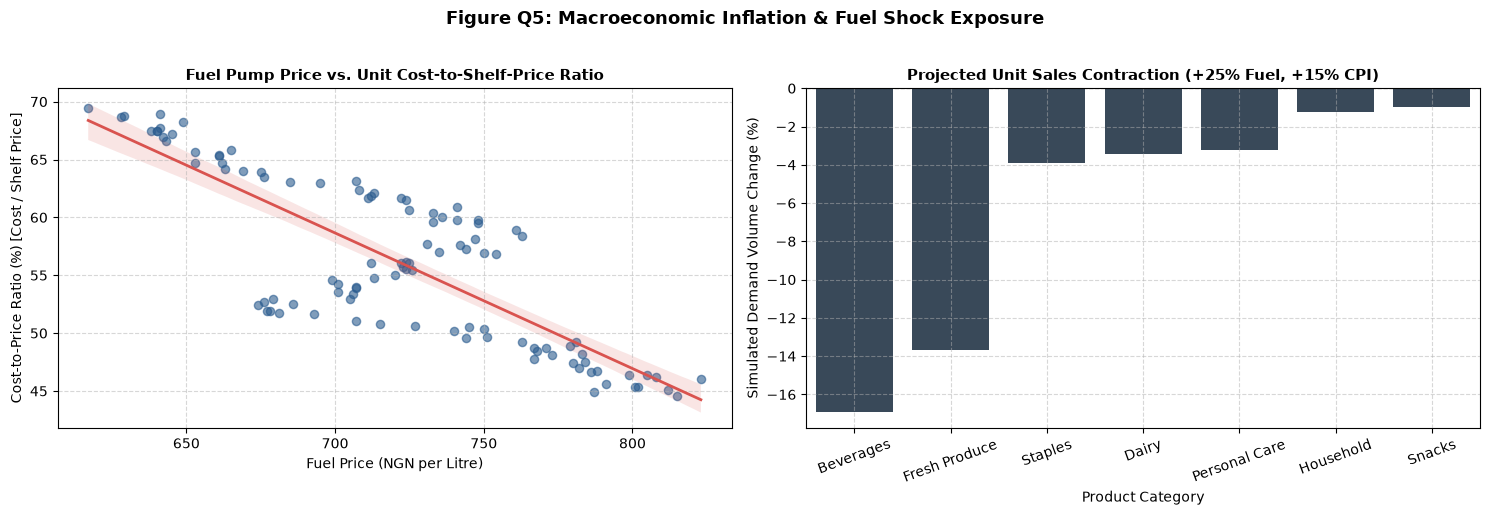

Figure Q5 exported cleanly to figures/fig_q5_macro_fuel_shocks.png


In [43]:
# -------------------------------------------------------------------------
# Step 5: Figure Q5 Visualization
# -------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left Panel: Cost-to-Price Ratio vs. Fuel Price
sns.regplot(
    data=macro_weekly,
    x='fuel_price',
    y='cost_to_price_ratio',
    scatter_kws={'alpha': 0.6, 'color': '#2b5c8f', 's': 35},
    line_kws={'color': '#d9534f', 'linewidth': 2},
    ax=axes[0]
)
axes[0].set_title('Fuel Pump Price vs. Unit Cost-to-Shelf-Price Ratio', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Fuel Price (NGN per Litre)')
axes[0].set_ylabel('Cost-to-Price Ratio (%) [Cost / Shelf Price]')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right Panel: Projected Volume Contraction
plot_macro = cat_macro_table.sort_values('Projected Volume Impact (%)', ascending=True)

sns.barplot(
    data=plot_macro,
    x='Category',
    y='Projected Volume Impact (%)',
    color='#34495e',
    ax=axes[1]
)
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Projected Unit Sales Contraction (+25% Fuel, +15% CPI)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Product Category')
axes[1].set_ylabel('Simulated Demand Volume Change (%)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Figure Q5: Macroeconomic Inflation & Fuel Shock Exposure', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

# Save at 300 DPI
plt.savefig('figures/fig_q5_macro_fuel_shocks.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure Q5 exported cleanly to figures/fig_q5_macro_fuel_shocks.png")